*رابط التطبيق المباشر (Streamlit):* https://nyc-airbnb-pricing-dhopmickyp8vywbcfpyt2e.streamlit.app

In [ ]:
import numpy as np
import pandas as pd

# قراءة الملف المرفوع في Colab
df = pd.read_csv('raw.csv')
print('حجم البيانات (صفوف، أعمدة):', df.shape)
print('\nأسماء الأعمدة وأنواعها:')
print(df.dtypes)

print('\n--- 1. القيم المفقودة ---')
missing = df.isnull().sum()
print(missing[missing > 0])

print('\n--- 2. الصفوف المكررة ---')
print('عدد التكرارات الكاملة:', df.duplicated().sum())
print('عدد معرفات الإعلان id المكررة:', df['id'].duplicated().sum())

print('\n--- 3. فحص السعر (price - Target) ---')
print('عدد الإعلانات بسعر <= 0:', (df['price'] <= 0).sum())
print(df['price'].describe())

print('\n--- 4. فحص الحد الأدنى لليالي (minimum_nights) ---')
print('عدد الإعلانات بـ minimum_nights > 365:', (df['minimum_nights'] > 365).sum())
print(df['minimum_nights'].describe())

حجم البيانات (صفوف، أعمدة): (48895, 16)

أسماء الأعمدة وأنواعها:
id                                  int64
name                               object
host_id                             int64
host_name                          object
neighbourhood_group                object
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                        object
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
dtype: object

--- 1. القيم المفقودة ---
name                    16
host_name               21
last_review          10052
reviews_per_month    10052
dtype: int64

--- 2. الصفوف المكررة ---
عدد التكرارات الكاملة: 0
عدد معرفات الإعلان id المكررة: 0

--- 3. فحص السع

سجل قرارات التنظيف (Decision Log):

1. المشكلة: أسعار صفرية في عمود الهدف (price <= 0).
- القرار: حذف هذه الصفوف.
- السبب بالرقم: يوجد 11 إعلاناً بسعر 0.0 من أصل 48,895 إعلاناً (والحد الأقصى 10,000).
- الصفوف المتأثرة: 11 صفاً.

2. المشكلة: نقص في reviews_per_month و last_review.
- القرار: تعبئة reviews_per_month بقيمة 0 (عدم وجود مراجعات شهرية).
- السبب بالرقم: يوجد 10,052 قيمة مفقودة في كلٍ من العمودين (حوالي 20.56% من 48,895 صفاً).
- الصفوف المتأثرة: 10,052 صفاً.

3. المشكلة: نقص في name و host_name.
- القرار: تعبئة القيم الناقصة بقيمة نصية (غير محدد) دون حذف الصفوف.
- السبب بالرقم: يوجد 16 نقصاً في name و 21 نقصاً في host_name من أصل 48,895 صفاً.
- الصفوف المتأثرة: 16 صفاً لـ name و 21 صفاً لـ host_name.

4. المشكلة: قيم مرتفعة في minimum_nights.
- القرار: الإبقاء عليها حالياً دون حذف عشوائي.
- السبب بالرقم: يوجد 14 صفاً فقط بـ minimum_nights > 365 (أقصاها 1,250 ليلة مقابل وسيط 3 ليالٍ).
- الصفوف المتأثرة: 14 صفاً (0 صفوف محذوفة).

تم إنشاء وحفظ data/clean.csv بنجاح: (48884, 16)

--- has_reviews vs price ---
              count        mean  median
has_reviews                            
No Reviews    10051  192.938215   120.0
With Reviews  38833  142.354595   101.0

--- stay_type vs price ---
                   count        mean  median
stay_type                                   
Long Stay (>7n)     7331  169.103124   120.0
Short Stay (<=7n)  41553  149.870840   103.0

--- host_type vs price ---
                count        mean  median
host_type                                
Multi Listing   16583  141.199602    93.0
Single Listing  32301  158.687502   119.0


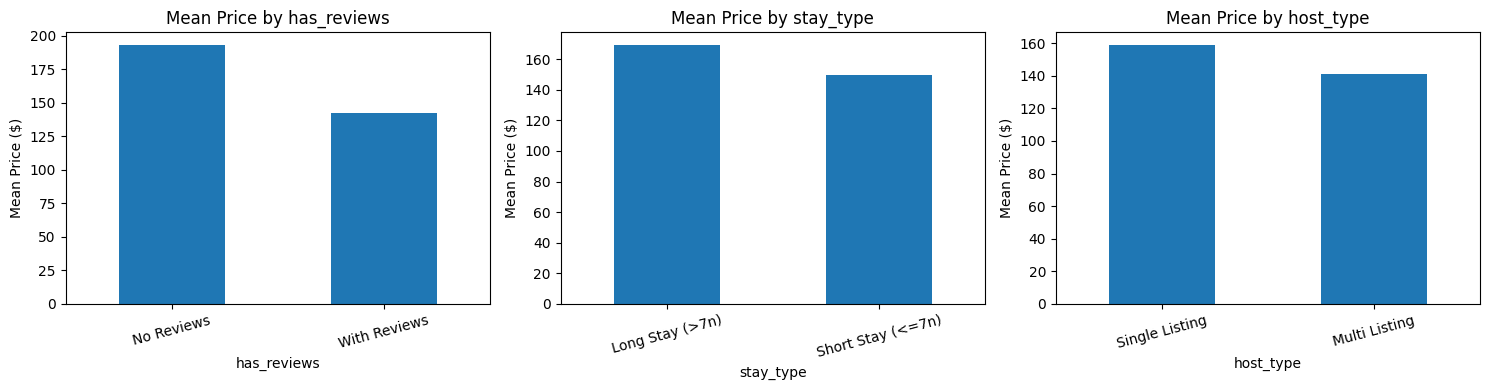

In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. قراءة الملف الخام المرفوع في Colab
df = pd.read_csv('raw.csv')

# 2. التنظيف الأساسي وحفظ data/clean.csv
df_clean = df[df['price'] > 0].copy()
df_clean['reviews_per_month'] = df_clean['reviews_per_month'].fillna(0)
df_clean['name'] = df_clean['name'].fillna('غير محدد')
df_clean['host_name'] = df_clean['host_name'].fillna('غير محدد')

os.makedirs('data', exist_ok=True)
df_clean.to_csv('data/clean.csv', index=False)
print('تم إنشاء وحفظ data/clean.csv بنجاح:', df_clean.shape)

# 3. إنشاء 3 أعمدة جديدة (Feature Engineering)
df_clean['has_reviews'] = np.where(
    df_clean['number_of_reviews'] > 0, 'With Reviews', 'No Reviews'
)
df_clean['stay_type'] = np.where(
    df_clean['minimum_nights'] <= 7, 'Short Stay (<=7n)', 'Long Stay (>7n)'
)
df_clean['host_type'] = np.where(
    df_clean['calculated_host_listings_count'] == 1,
    'Single Listing',
    'Multi Listing',
)

features = ['has_reviews', 'stay_type', 'host_type']

for col in features:
  print(f'\n--- {col} vs price ---')
  print(
      df_clean.groupby(col)['price'].agg(
          count='count', mean='mean', median='median'
      )
  )

# 4. رسم علاقة الأعمدة الجديدة بمتوسط السعر
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, features):
  means = df_clean.groupby(col)['price'].mean().sort_values(ascending=False)
  means.plot(kind='bar', ax=ax)
  ax.set_title(f'Mean Price by {col}')
  ax.set_ylabel('Mean Price ($)')
  ax.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

هندسة الخصائص (Feature Engineering):

1. العمود الجديد: has_reviews (هل الإعلان عليه مراجعات أم لا؟)
- لماذا أضفته؟ لمعرفة ما إذا كان تسعير الإعلانات التي لم تحصل على مراجعات يختلف عن الإعلانات ذات المراجعات السابقة.
- علاقته بالسعر (برقم): الإعلانات بدون مراجعات (No Reviews، وعددها 10,051) يبلغ متوسط سعرها 192.94$ والوسيط 120.0$، مقابل متوسط 142.35$ والوسيط 101.0$ للإعلانات ذات المراجعات (With Reviews، وعددها 38,833).

2. العمود الجديد: stay_type (نوع الإقامة حسب الحد الأدنى لليالي)
- لماذا أضفته؟ لتمييز الإقامات القصيرة (7 ليالٍ أو أقل) عن الإقامات الأطول (أكثر من 7 ليالٍ) وفحص أثر مدة الإقامة على سعر الليلة.
- علاقته بالسعر (برقم): إقامات Long Stay (>7n) (وعددها 7,331) يبلغ متوسط سعرها 169.10$ والوسيط 120.0$، بينما إقامات Short Stay (<=7n) (وعددها 41,553) متوسط سعرها 149.87$ والوسيط 103.0$.

3. العمود الجديد: host_type (هل المضيف صاحب إعلان واحد أم عدة إعلانات؟)
- لماذا أضفته؟ لمعرفة الفارق في التسعير بين المضيفين الفرديين والمضيفين ذوي الإعلانات المتعددة.
- علاقته بالسعر (برقم): الإعلانات الفردية Single Listing (وعددها 32,301) يبلغ متوسط سعرها 158.69$ والوسيط 119.0$، مقابل متوسط 141.20$ والوسيط 93.0$ للإعلانات المتعددة Multi Listing (وعددها 16,583).

عدد الأعمدة قبل الحذف: 19
عدد الأعمدة بعد الحذف: 14
الأعمدة المحذوفة: ['id', 'host_id', 'name', 'host_name', 'last_review']

الأعمدة المتبقية في data/model_ready.csv:
['neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'has_reviews', 'stay_type', 'host_type']

معامل الارتباط مع السعر (price):
longitude                        -0.149954
reviews_per_month                -0.050531
number_of_reviews                -0.047926
latitude                          0.033899
minimum_nights                    0.042805
calculated_host_listings_count    0.057462
availability_365                  0.081847
Name: price, dtype: float64


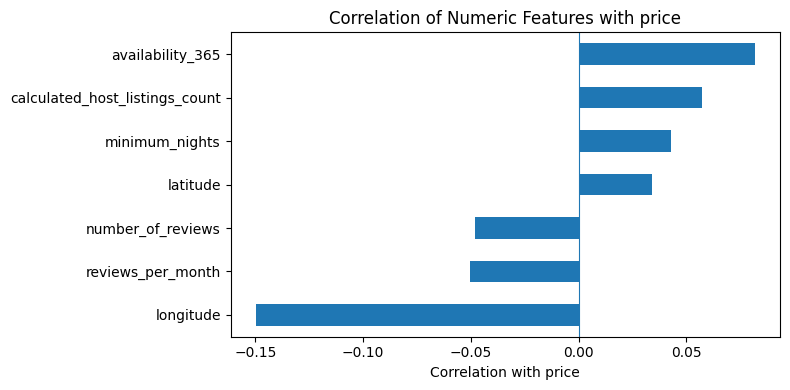

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. قراءة البيانات النظيفة
df_mr = pd.read_csv('data/clean.csv')

# إعادة إنشاء الأعمدة الثلاثة الجديدة للتأكد من وجودها في df_mr
df_mr['has_reviews'] = np.where(
    df_mr['number_of_reviews'] > 0, 'With Reviews', 'No Reviews'
)
df_mr['stay_type'] = np.where(
    df_mr['minimum_nights'] <= 7, 'Short Stay (<=7n)', 'Long Stay (>7n)'
)
df_mr['host_type'] = np.where(
    df_mr['calculated_host_listings_count'] == 1,
    'Single Listing',
    'Multi Listing',
)

# 2. تحديد الأعمدة المراد حذفها (معرفات، أسماء، وتاريخ آخر مراجعة)
cols_to_drop = ['id', 'host_id', 'name', 'host_name', 'last_review']
df_model_ready = df_mr.drop(columns=cols_to_drop).copy()

# حفظ الناتج في data/model_ready.csv
model_ready_path = 'data/model_ready.csv'
df_model_ready.to_csv(model_ready_path, index=False)

print('عدد الأعمدة قبل الحذف:', df_mr.shape[1])
print('عدد الأعمدة بعد الحذف:', df_model_ready.shape[1])
print('الأعمدة المحذوفة:', cols_to_drop)
print('\nالأعمدة المتبقية في data/model_ready.csv:')
print(list(df_model_ready.columns))

# 3. رسمة داعمة للقرار: ارتباط المتغيرات الرقمية مع السعر (price)
numeric_cols = df_model_ready.select_dtypes(include=[np.number]).columns
corr_with_price = (
    df_model_ready[numeric_cols]
    .corr()['price']
    .drop('price')
    .sort_values()
)

print('\nمعامل الارتباط مع السعر (price):')
print(corr_with_price)

plt.figure(figsize=(8, 4))
corr_with_price.plot(kind='barh')
plt.title('Correlation of Numeric Features with price')
plt.xlabel('Correlation with price')
plt.axvline(0, linewidth=0.8)
plt.tight_layout()
plt.show()

قرارات اختيار الخصائص (Feature Selection - القسم 7):
- الملف النهائي المحفوظ: data/model_ready.csv[span_1](start_span)[span_1](end_span)
- عدد الأعمدة: من 19 عموداً إلى 14 عموداً (حذف 5 أعمدة والاحتفاظ بـ 14 عموداً)[span_2](start_span)[span_2](end_span)

أولاً: الأعمدة المحذوفة (5 أعمدة)[span_3](start_span)[span_3](end_span):
1. id و host_id:
   - القرار: حذف.
   - السبب والرقم: معرفات رقمية لا تحمل دلالة تسعيرية (على 48,884 صفاً، و0 تكرارات في البيانات الخام).
2. name و host_name:
   - القرار: حذف.
   - السبب والرقم: أسماء ونصوص وصفية متغيرة لكل إعلان (كان فيهما 16 و 21 قيمة مفقودة في البيانات الخام).
3. last_review:
   - القرار: حذف.
   - السبب والرقم: تاريخ آخر مراجعة يكرر معلومة النشاط التي تم تغطيتها بعمود has_reviews و reviews_per_month (كان فيه 10,052 قيمة مفقودة في البيانات الخام).

ثانياً: الأعمدة المحتفَظ بها (14 عموداً)[span_4](start_span)[span_4](end_span):
- الهدف: price (المتغير المستهدف لتنبؤ سعر الليلة).
- الموقع ونوع الوحدة: neighbourhood_group، neighbourhood، latitude (معامل الارتباط مع السعر +0.033899)، longitude (معامل الارتباط مع السعر -0.149954 وهو الأقوى عكسياً بين المتغيرات الرقمية المرسومة)، room_type[span_5](start_span)[span_5](end_span).
- النشاط والإتاحة والمضيف: availability_365 (معامل الارتباط +0.081847 وهو الأعلى طردياً بين المتغيرات الرقمية المرسومة)، calculated_host_listings_count (معامل الارتباط +0.057462)، minimum_nights (معامل الارتباط +0.042805)، number_of_reviews (معامل الارتباط -0.047926)، reviews_per_month (معامل الارتباط -0.050531)[span_6](start_span)[span_6](end_span).
- الأعمدة الجديدة (Feature Engineering): has_reviews، stay_type، host_type (لأنها أظهرت فروقاً واضحة في متوسط ووسيط السعر).

In [ ]:
import pandas as pd

df = pd.read_csv('model_ready.csv')
print("عدد الصفوف والأعمدة:", df.shape)
print("\nمتوسط ووسيط السعر حسب الحي (neighbourhood_group):")
print(df.groupby('neighbourhood_group')['price'].agg(['count', 'mean', 'median']))
print("\nمتوسط ووسيط السعر حسب نوع الغرفة (room_type):")
print(df.groupby('room_type')['price'].agg(['count', 'mean', 'median']))
print("\nمتوسط ووسيط السعر حسب الخصائص الهندسية الجديدة:")
for col in ['has_reviews', 'stay_type', 'host_type']:
    if col in df.columns:
        print(f"\n--- {col} ---")
        print(df.groupby(col)['price'].agg(['count', 'mean', 'median']))

عدد الصفوف والأعمدة: (48884, 14)

متوسط ووسيط السعر حسب الحي (neighbourhood_group):
                     count        mean  median
neighbourhood_group                           
Bronx                 1090   87.577064    65.0
Brooklyn             20095  124.438915    90.0
Manhattan            21660  196.884903   150.0
Queens                5666   99.517649    75.0
Staten Island          373  114.812332    75.0

متوسط ووسيط السعر حسب نوع الغرفة (room_type):
                 count        mean  median
room_type                                 
Entire home/apt  25407  211.810918   160.0
Private room     22319   89.809131    70.0
Shared room       1158   70.248705    45.0

متوسط ووسيط السعر حسب الخصائص الهندسية الجديدة:

--- has_reviews ---
              count        mean  median
has_reviews                            
No Reviews    10051  192.938215   120.0
With Reviews  38833  142.354595   101.0

--- stay_type ---
                   count        mean  median
stay_type                      

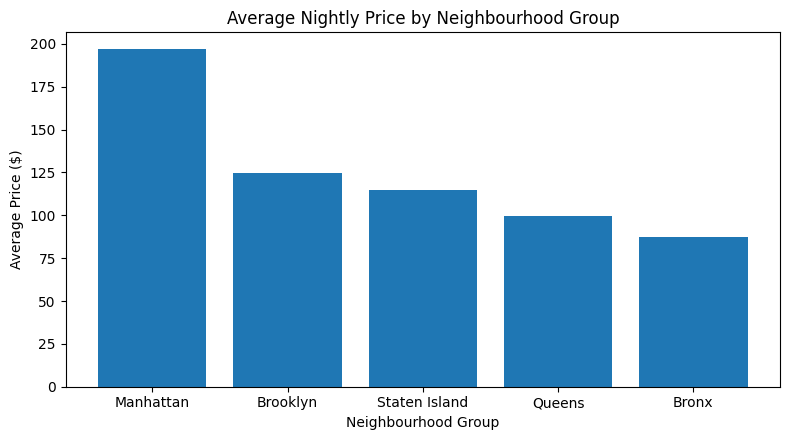

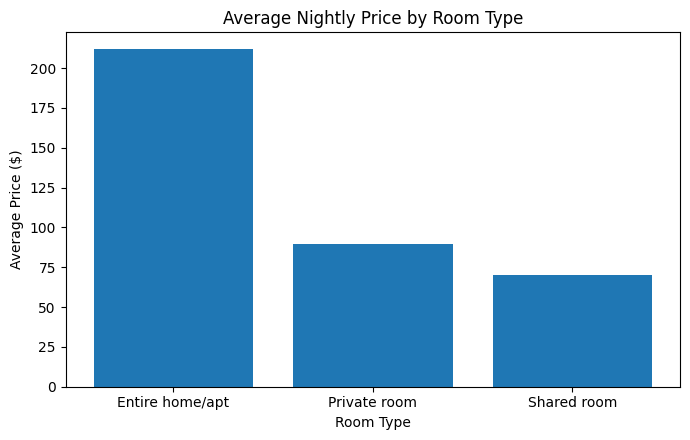

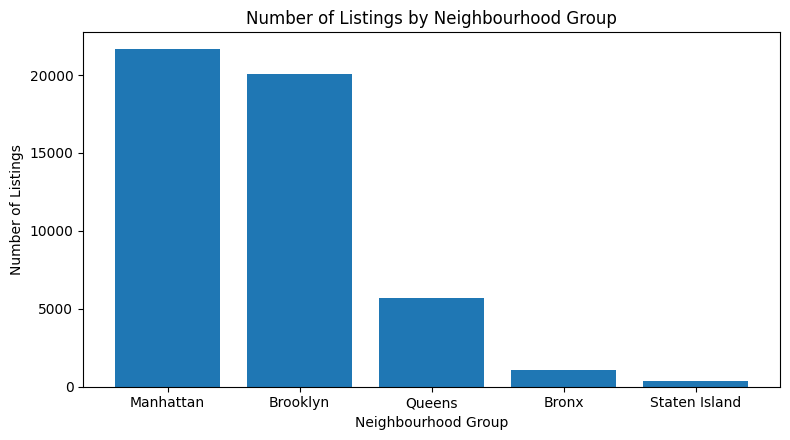

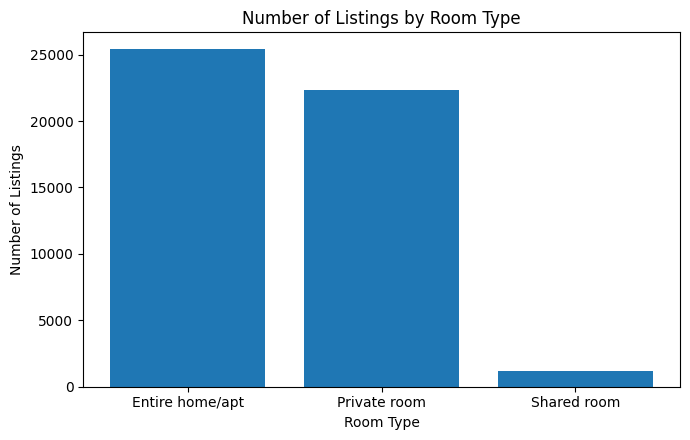

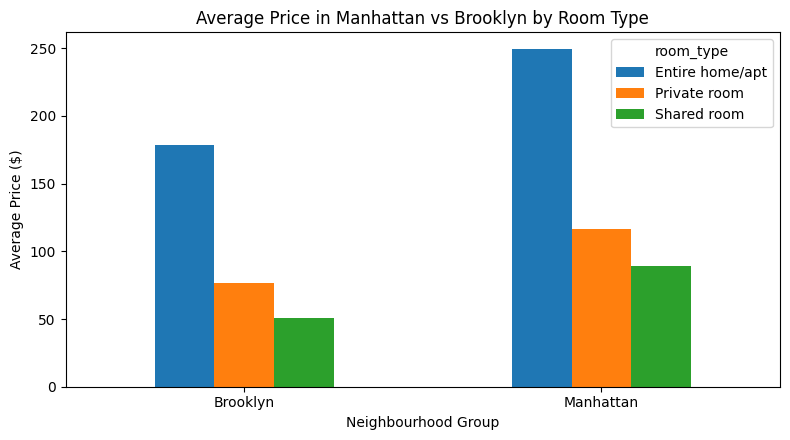

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('model_ready.csv')

# 1. متوسط السعر حسب الحي
neigh_mean = df.groupby('neighbourhood_group')['price'].mean().sort_values(ascending=False)
plt.figure(figsize=(8, 4.5))
plt.bar(neigh_mean.index, neigh_mean.values)
plt.title('Average Nightly Price by Neighbourhood Group')
plt.xlabel('Neighbourhood Group')
plt.ylabel('Average Price ($)')
plt.tight_layout()
plt.show()

# 2. متوسط السعر حسب نوع الغرفة
room_mean = df.groupby('room_type')['price'].mean().sort_values(ascending=False)
plt.figure(figsize=(7, 4.5))
plt.bar(room_mean.index, room_mean.values)
plt.title('Average Nightly Price by Room Type')
plt.xlabel('Room Type')
plt.ylabel('Average Price ($)')
plt.tight_layout()
plt.show()

# 3. عدد الإعلانات حسب الحي
neigh_count = df['neighbourhood_group'].value_counts()
plt.figure(figsize=(8, 4.5))
plt.bar(neigh_count.index, neigh_count.values)
plt.title('Number of Listings by Neighbourhood Group')
plt.xlabel('Neighbourhood Group')
plt.ylabel('Number of Listings')
plt.tight_layout()
plt.show()

# 4. توزيع أنواع الغرف
room_count = df['room_type'].value_counts()
plt.figure(figsize=(7, 4.5))
plt.bar(room_count.index, room_count.values)
plt.title('Number of Listings by Room Type')
plt.xlabel('Room Type')
plt.ylabel('Number of Listings')
plt.tight_layout()
plt.show()

# 5. متوسط السعر في مانهاتن وبروكلين حسب نوع الغرفة
top_two = df[df['neighbourhood_group'].isin(['Manhattan', 'Brooklyn'])]
pivot_price = top_two.pivot_table(index='neighbourhood_group', columns='room_type', values='price', aggfunc='mean')
pivot_price.plot(kind='bar', figsize=(8, 4.5))
plt.title('Average Price in Manhattan vs Brooklyn by Room Type')
plt.xlabel('Neighbourhood Group')
plt.ylabel('Average Price ($)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 8. الاكتشافات

### الاكتشاف 1: تفوق مانهاتن في متوسط سعر الليلة
- *الاكتشاف:* متوسط سعر الليلة في *Manhattan* يبلغ *196.88$* (والوسيط *150.0$) مقابل **87.58$* (والوسيط *65.0$) في **Bronx* و*99.52$* في *Queens*.
- *الرسمة:* Average Nightly Price by Neighbourhood Group (الموقع على المحور الأفقي ومتوسط السعر بالدولار على المحور الرأسي).
- *ماذا يعني للعميل؟* يمكن للعميل تسعير الوحدات في مانهاتن بمستويات أعلى مع التركيز على تنافسية السعر في كوينز والبرونكس لجذب الباحثين عن خيارات اقتصادية.

### الاكتشاف 2: قفزة السعر في الشقق والوحدات الكاملة
- *الاكتشاف:* متوسط سعر الليلة لـ *Entire home/apt* يبلغ *211.81$* (والوسيط *160.0$) مقابل **89.81$* لـ *Private room* و*70.25$* لـ *Shared room*.
- *الرسمة:* Average Nightly Price by Room Type (نوع الغرفة على المحور الأفقي ومتوسط السعر بالدولار على المحور الرأسي).
- *ماذا يعني للعميل؟* يعتمد تسعير الإعلان بشكل أساسي على نوع الوحدة، لذا يجب فصل نماذج أو شرائح التسعير بين الوحدات الكاملة والغرف المشتركة أو الخاصة.

### الاكتشاف 3: تركز العرض السوقي في مانهاتن وبروكلين
- *الاكتشاف:* تستحوذ *Manhattan* على *21,660* إعلاناً و*Brooklyn* على *20,095* إعلاناً من إجمالي *48,884* إعلاناً (أكثر من *85%* من السوق)، مقابل *5,666* في *Queens* و*1,090* في *Bronx* و*373* في *Staten Island*.
- *الرسمة:* Number of Listings by Neighbourhood Group (الحي على المحور الأفقي وعدد الإعلانات على المحور الرأسي).
- *ماذا يعني للعميل؟* المنافسة أعلى بكثير في مانهاتن وبروكلين، مما يتطلب تسعيراً دقيقاً ومميزاً حتى لا يضعف الإقبال على الإعلان.

### الاكتشاف 4: هيمنة الوحدات الكاملة والغرف الخاصة على المعروض
- *الاكتشاف:* يبلغ عدد إعلانات *Entire home/apt* نحو *25,407* إعلاناً و*Private room* نحو *22,319* إعلاناً مقابل *1,158* إعلاناً فقط لـ *Shared room*.
- *الرسمة:* Number of Listings by Room Type (نوع الغرفة على المحور الأفقي وعدد الإعلانات على المحور الرأسي).
- *ماذا يعني للعميل؟* عند تقدير سعر وحدة كاملة أو غرفة خاصة يجب مقارنة الإعلان ضمن فئته الكبيرة لتجنب المبالغة في السعر أو تسعيره بأقل من قيمته السوقية.

### الاكتشاف 5: اتساع فجوة السعر بين مانهاتن وبروكلين حسب نوع الوحدة
- *الاكتشاف:* في *Manhattan* يصل متوسط سعر *Entire home/apt* إلى قرابة *249$* مقابل حوالي *178$* في *Brooklyn، بينما يبلغ متوسط **Private room* نحو *116$* في مانهاتن مقابل حوالي *77$* في بروكلين.
- *الرسمة:* Average Price in Manhattan vs Brooklyn by Room Type (الحي على المحور الأفقي ومتوسط السعر بالدولار على المحور الرأسي حسب نوع الغرفة).
- *ماذا يعني للعميل؟* يجب دمج الموقع مع نوع الغرفة عند تحديد السعر المقترح، لأن نفس نوع الغرفة يختلف تسعيره بوضوح بين مانهاتن وبروكلين.

### إجابة صريحة بالأرقام عن سؤالي العميل في وصف المشكلة:
- *السؤال الأول (ما العوامل الرئيسية المؤثرة في سعر الليلة؟):* يبرز *نوع الغرفة (room_type)* و*الحي (neighbourhood_group)* كأقوى محددات للسعر؛ إذ يرتفع متوسط السعر من *70.25$* للغرفة المشتركة إلى *211.81$* للوحدة الكاملة، ومن *87.58$* في البرونكس إلى *196.88$* في مانهاتن (كما يظهر أثر الموقع الرقمي في longitude بمعامل ارتباط *-0.149954*).
- *السؤال الثاني (كيف نحدد سعراً عادلاً ومنطقياً للإعلان لتجنب ضعف الإقبال أو خسارة العائد؟):* بالاستناد إلى *الوسيط والمتوسط* حسب الحي ونوع الوحدة (مثلاً وسيط *150.0$* في مانهاتن مقابل *90.0$* في بروكلين، ووسيط *160.0$* للوحدة الكاملة مقابل *70.0$* للغرفة الخاصة) لتفادي التسعير المبالغ فيه الذي يضعف الحجز أو التسعير المنخفض الذي يقلص العائد.

## 9. التوصيات

1. *ربط نطاق التسعير المقترح بالحي ونوع الغرفة معاً:* بناءً على أن متوسط سعر الوحدة الكاملة يبلغ *211.81$* مقابل *89.81$* للغرفة الخاصة، وأن مانهاتن تبلغ *196.88$* مقابل *124.44$* في بروكلين، يُنصح بتقديم نطاق سعري مرن يستند إلى الوسيط والمتوسط لكل فئة لتجنب المبالغة أو التفويت في العائد.
2. *التركيز على التمايز السعري في الأسواق عالية الكثافة:* نظراً لأن *Manhattan* (*21,660* إعلاناً) و*Brooklyn* (*20,095* إعلاناً) يضمان أكثر من *85%* من إجمالي *48,884* إعلاناً، يُنصح بمقارنة الإعلان بالمنافسين المباشرين في نفس الحي ونوع الغرفة قبل اعتماد السعر النهائي.
3. *تخصيص استراتيجية تسعير للخيارات الاقتصادية في الأحياء الأقل سعراً:* بالنظر إلى أن متوسط السعر في *Bronx* يبلغ *87.58$* وفي *Queens* *99.52$* وأن الغرف المشتركة بمتوسط *70.25$*، يُنصح بالاعتماد على تسعير تنافسي واضح يبرز القيمة مقابل السعر لجذب الحجوزات.

- *ما لا تستطيع البيانات قوله:* ارتفاع سعر الإعلان أو ارتباط متغير معين بالسعر في البيانات لا يثبت وحده أن السعر أو المتغير هو السبب المباشر لزيادة أو نقص الحجوزات، لأن الارتباط ليس سبباً وقد تتدخل عوامل أخرى غير مرصودة مثل جودة الصور أو التقييمات أو الموسمية.